# Multi-start aléatoire — V1LD

Compare N_STARTS initialisations aléatoires de λ ∈ R^{N_z × n_g}, chacune
convergée par sous-gradient (precision=1, patience=30), avec cold-start λ=0
et un overfit GNN.

**Différence V1CLD → V1LD** : λ n'a plus de dimension de contrainte (shape
`(N_z, n_g)` au lieu de `(N_z, m, n_g)`). Le sous-problème ζ_i est un
knapsack multi-dimensionnel (B&B exact).

## 1. Setup

In [8]:
import sys, importlib
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

REPO = Path("../").resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import gnn.train_gnn_v1ld as T
importlib.reload(T)

from gnn.train_gnn_v1ld import (
    load_dataset, GNN, lagrangian_v1ld, verify_v1ld,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

## 2. Chargement des données

In [ ]:
N_VAL = 10

def _data_dir(n):
    p_new = REPO / "data" / "train_v1ld" / f"instances_n{n}.txt"
    return (REPO / "data" / "train_v1ld") if p_new.exists() else (REPO / "data" / "train_v1LD")

DATA_DIR = _data_dir(N_VAL)
print(f"DATA_DIR = {DATA_DIR}")

graphs = load_dataset(
    DATA_DIR / f"instances_n{N_VAL}.txt",
    DATA_DIR / f"nodes_n{N_VAL}.txt",
)

print(f"\n{'idx':>4}  {'depth':>5}  {'n_g':>4}  {'N_z':>4}  {'N':>4}  {'m':>3}  {'n_fix_z1':>9}  {'opt':>8}")
print("-" * 60)
for i, g in enumerate(graphs):
    print(f"{i:4d}  {int(g.context[0].item()):5d}  {g.n_g:4d}  {g.N_z:4d}  {g.N:4d}  {g.m:3d}  "
          f"{g.n_fixed_z1:9d}  {g.opt.item():8.2f}")

DATA_DIR = /Users/roman.lendormy/Documents/Cours/X25 - 3A/Stage/Learning_bounds_CCCP/data/train_v1ld


## 3. Sélection du graphe et référence cold-start

In [ ]:
GRAPH_IDX = 0
g = graphs[GRAPH_IDX]

with torch.no_grad():
    lam0    = torch.zeros(g.N_z * g.n_g)   # shape (N_z*n_g,) pour V1LD
    l1_init = lagrangian_v1ld(lam0, g).item()

opt_val      = g.opt.item()
curr_cost    = g.context[3].item()
opt_residual = opt_val - curr_cost
depth        = int(g.context[0].item())

PRECISION = 1
PATIENCE  = 30

print(f"Graphe {GRAPH_IDX}  (depth={depth}, n_g={g.n_g}, N_z={g.N_z}, N={g.N}, m={g.m})")
print(f"  curr_cost    = {curr_cost:.2f}")
print(f"  opt (global) = {opt_val:.2f}")
print(f"  opt_residuel = {opt_residual:.2f}  (= opt - curr_cost)")
print(f"  L1(lam=0)    = {l1_init:.2f}")
print(f"  lam shape    = ({g.N_z}, {g.n_g})  [N_z x n_g, pas de dim. contrainte]")
print()
print("Cold-start (lam=0) convergence...")
l1_cold, n_cold = verify_v1ld(
    g, T=500, precision=PRECISION, patience=PATIENCE, return_n_iters=True)
print(f"  converged : {l1_cold:.2f}  ({n_cold} it.)  amelioration {(l1_init - l1_cold)/l1_init*100:.1f}% vs L1(0)")

## 4. Multi-start aléatoire

λ ~ U(−RAND_STD, +RAND_STD) de shape `(N_z, n_g)` (sans dimension de contrainte).

In [ ]:
N_STARTS = 10
RAND_STD = 3.0   # ordre de grandeur de lambda a convergence : ~2-5
SEED     = 0

rng = np.random.default_rng(SEED)
lam_shape = (g.N_z, g.n_g)   # V1LD : pas de dimension m

rand_l1_before = []
rand_l1_conv   = []
rand_n_iters   = []

print(f"{'run':>4}  {'L1_init_rand':>14}  {'L1_conv':>10}  {'n_iters':>8}  {'amelioration':>13}")
print("-" * 60)

for run in range(N_STARTS):
    lam_rand = rng.uniform(-RAND_STD, RAND_STD, size=lam_shape).astype(np.float64)

    with torch.no_grad():
        l1_r = lagrangian_v1ld(
            torch.tensor(lam_rand.reshape(-1), dtype=torch.float32), g
        ).item()

    l1_c, n_it = verify_v1ld(
        g, T=500, lam_init=lam_rand,
        precision=PRECISION, patience=PATIENCE, return_n_iters=True)

    rand_l1_before.append(l1_r)
    rand_l1_conv.append(l1_c)
    rand_n_iters.append(n_it)

    print(f"{run:4d}  {l1_r:14.2f}  {l1_c:10.2f}  {n_it:8d}  {(l1_r - l1_c)/max(abs(l1_r),1e-9)*100:+12.1f}%")

rand_l1_before = np.array(rand_l1_before)
rand_l1_conv   = np.array(rand_l1_conv)

 run    L1_init_rand     L1_conv   n_iters   amelioration
------------------------------------------------------------
   0         3396.30     2943.14       500         +13.3%
   1         3379.14     2942.58       500         +12.9%
   2         3380.66     2942.18       500         +13.0%
   3         3418.84     2942.61       500         +13.9%
   4         3400.59     2942.51       500         +13.5%
   5         3383.89     2941.78       500         +13.1%
   6         3395.47     2944.03       500         +13.3%
   7         3391.65     2940.82       500         +13.3%
   8         3403.35     2943.81       500         +13.5%
   9         3390.77     2942.70       500         +13.2%


## 5. Tableau récapitulatif

In [ ]:
W = 52

def fmt_row(label, val, ref=None, l0=None):
    ref = opt_residual if ref is None else ref
    l0  = l1_init     if l0  is None else l0
    gap_res = (val - ref) / max(abs(ref), 1e-9) * 100
    gap_l0  = (val - l0)  / max(abs(l0),  1e-9) * 100
    return f"{label:>{W}}   {val:10.2f}   {gap_res:+9.1f}%   {gap_l0:+9.1f}%"

print(f"{'':>{W}}   {'L1_res':>10}   {'vs opt_res':>10}   {'vs L1(0)':>10}")
print("-" * (W + 42))
print(fmt_row("L1(lam=0)  [cold-start depart]",     l1_init))
print(fmt_row("Cold-start converge",                 l1_cold))
print("-" * (W + 42))
print(fmt_row(f"Aleatoire mean   (N={N_STARTS}, avant conv.)",  rand_l1_before.mean()))
print(fmt_row(f"Aleatoire best   (N={N_STARTS}, avant conv.)",  rand_l1_before.min()))
print(fmt_row(f"Aleatoire worst  (N={N_STARTS}, avant conv.)",  rand_l1_before.max()))
print("-" * (W + 42))
print(fmt_row(f"Aleatoire conv mean   (N={N_STARTS})",          rand_l1_conv.mean()))
print(fmt_row(f"Aleatoire conv best   (N={N_STARTS})",          rand_l1_conv.min()))
print(fmt_row(f"Aleatoire conv worst  (N={N_STARTS})",          rand_l1_conv.max()))
print(fmt_row(f"Aleatoire conv std    (N={N_STARTS})",
              rand_l1_conv.std(), ref=rand_l1_conv.std(), l0=rand_l1_conv.std()))
print("-" * (W + 42))
label_opt = f"opt_residuel = opt-curr_cost  [{opt_val:.0f}-{curr_cost:.0f}]"
print(fmt_row(label_opt, opt_residual))

print()
cmp = "mieux" if rand_l1_conv.min() < l1_cold else "moins bon ou egal"
print(f"Best aleatoire conv vs cold-start conv : {rand_l1_conv.min():.2f} vs {l1_cold:.2f}  ({cmp})")

                                                           L1_res   vs opt_res     vs L1(0)
----------------------------------------------------------------------------------------------
                      L1(lam=0)  [cold-start depart]      3307.53       +58.6%        +0.0%
                                 Cold-start converge      2940.62       +41.0%       -11.1%
----------------------------------------------------------------------------------------------
                Aleatoire mean   (N=10, avant conv.)      3394.07       +62.8%        +2.6%
                Aleatoire best   (N=10, avant conv.)      3379.14       +62.0%        +2.2%
                Aleatoire worst  (N=10, avant conv.)      3418.84       +63.9%        +3.4%
----------------------------------------------------------------------------------------------
                        Aleatoire conv mean   (N=10)      2942.62       +41.1%       -11.0%
                        Aleatoire conv best   (N=10)      2940.82      

## 6. Visualisation

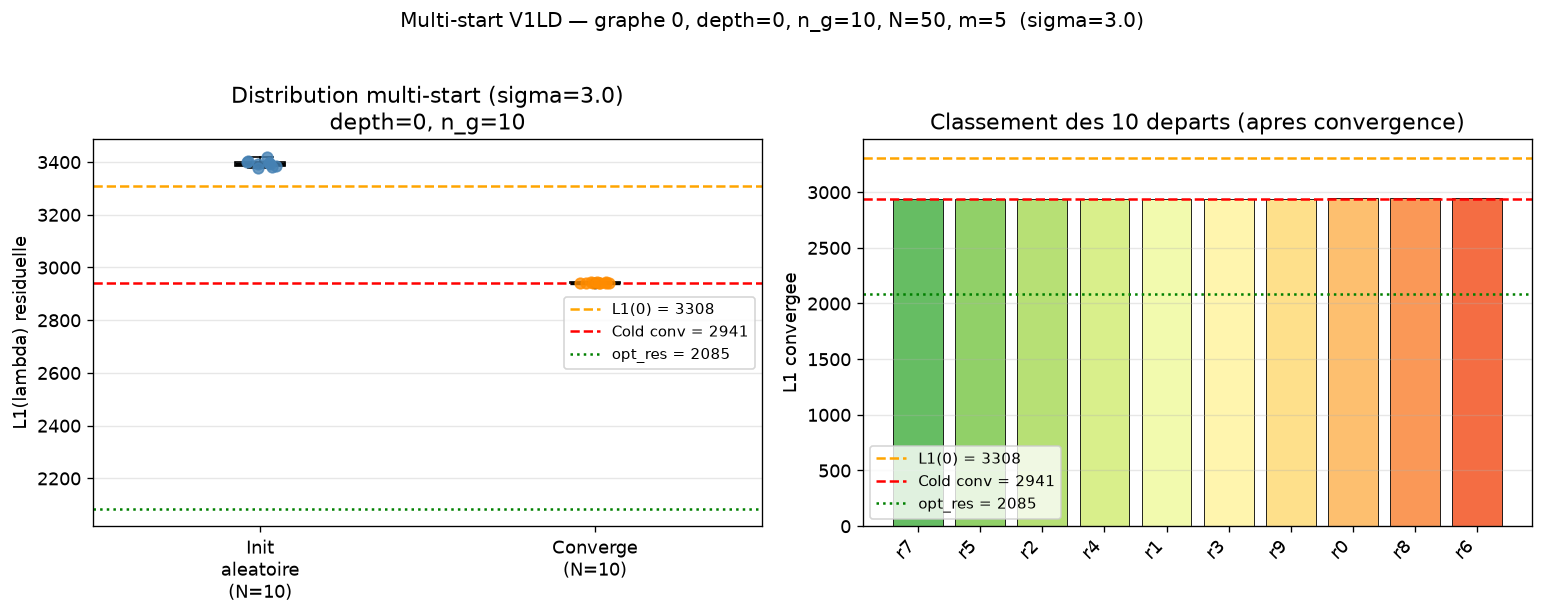

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
bp = ax.boxplot(
    [rand_l1_before, rand_l1_conv],
    tick_labels=[f"Init\naleatoire\n(N={N_STARTS})", f"Converge\n(N={N_STARTS})"],
    patch_artist=True,
    medianprops=dict(color="black", lw=2),
)
bp["boxes"][0].set_facecolor("#aec6e8")
bp["boxes"][1].set_facecolor("#ffb347")

rng_jitter = np.random.default_rng(42)
jitter = 0.05
ax.scatter(np.ones(N_STARTS) + rng_jitter.uniform(-jitter, jitter, N_STARTS),
           rand_l1_before, color="steelblue", zorder=3, s=40, alpha=0.8)
ax.scatter(np.ones(N_STARTS)*2 + rng_jitter.uniform(-jitter, jitter, N_STARTS),
           rand_l1_conv, color="darkorange", zorder=3, s=40, alpha=0.8)

ax.axhline(l1_init,      color="orange", lw=1.5, ls="--", label=f"L1(0) = {l1_init:.0f}")
ax.axhline(l1_cold,      color="red",    lw=1.5, ls="--", label=f"Cold conv = {l1_cold:.0f}")
ax.axhline(opt_residual, color="green",  lw=1.5, ls=":",  label=f"opt_res = {opt_residual:.0f}")
ax.set_ylabel("L1(lambda) residuelle")
ax.set_title(f"Distribution multi-start (sigma={RAND_STD})\ndepth={depth}, n_g={g.n_g}")
ax.legend(fontsize=9)
ax.grid(True, axis="y", alpha=0.3)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))

ax2 = axes[1]
order  = np.argsort(rand_l1_conv)
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, N_STARTS))
ax2.bar(range(N_STARTS), rand_l1_conv[order], color=colors, edgecolor="black", lw=0.5)
ax2.axhline(l1_init,      color="orange", lw=1.5, ls="--", label=f"L1(0) = {l1_init:.0f}")
ax2.axhline(l1_cold,      color="red",    lw=1.5, ls="--", label=f"Cold conv = {l1_cold:.0f}")
ax2.axhline(opt_residual, color="green",  lw=1.5, ls=":",  label=f"opt_res = {opt_residual:.0f}")
ax2.set_xticks(range(N_STARTS))
ax2.set_xticklabels([f"r{order[i]}" for i in range(N_STARTS)], rotation=45, ha="right")
ax2.set_ylabel("L1 convergee")
ax2.set_title(f"Classement des {N_STARTS} departs (apres convergence)")
ax2.legend(fontsize=9)
ax2.grid(True, axis="y", alpha=0.3)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))

plt.suptitle(
    f"Multi-start V1LD — graphe {GRAPH_IDX}, depth={depth}, n_g={g.n_g}, N={g.N}, m={g.m}  (sigma={RAND_STD})",
    fontsize=12, y=1.02
)
plt.tight_layout()
plt.savefig(REPO / "gnn" / "multistart_v1ld.png", bbox_inches="tight")
plt.show()

## 7. Overfit GNN sur ce graphe

In [ ]:
N_EPOCHS = 1000
LR       = 1e-3

torch.manual_seed(42)
device = torch.device("cpu")
data   = g.to(device)

# GNN V1LD prend m comme parametre (NODE_DIM = 5m+3)
model     = GNN(m=data.m).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
sched     = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS, eta_min=1e-5)

for epoch in range(1, N_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    lam  = model(data)
    loss = lagrangian_v1ld(lam, data)
    loss.backward()
    optimizer.step()
    sched.step()
    if epoch % 200 == 0 or epoch == 1:
        print(f"  epoch {epoch:4d}  L1={loss.item():.2f}")

final_l1_gnn = loss.item()

W = 45
print(f"\n{'':>{W}}   {'L1_res':>10}   {'vs opt_res':>10}   {'vs L1(0)':>10}")
print("-" * (W + 42))

def row(label, val):
    gap_res = (val - opt_residual) / max(abs(opt_residual), 1e-9) * 100
    gap_l0  = (val - l1_init)      / max(abs(l1_init),      1e-9) * 100
    return f"{label:>{W}}   {val:10.2f}   {gap_res:+9.1f}%   {gap_l0:+9.1f}%"

print(row("L1(lam=0)",                              l1_init))
print(row("Cold-start converge",                    l1_cold))
print("-" * (W + 42))
print(row(f"Random U(-{RAND_STD},{RAND_STD}) mean conv  (N={N_STARTS})", rand_l1_conv.mean()))
print(row(f"Random U(-{RAND_STD},{RAND_STD}) best conv  (N={N_STARTS})", rand_l1_conv.min()))
print(row(f"Random U(-{RAND_STD},{RAND_STD}) worst conv (N={N_STARTS})", rand_l1_conv.max()))
print("-" * (W + 42))
print(row(f"GNN overfit ({N_EPOCHS} epochs, lr={LR})",   final_l1_gnn))
print("-" * (W + 42))
label_opt = f"opt_residuel = opt-curr_cost  [{opt_val:.0f}-{curr_cost:.0f}]"
print(row(label_opt,                                opt_residual))

  epoch    1  L1=3307.45
  epoch  200  L1=3002.31
  epoch  400  L1=2930.09
  epoch  600  L1=2908.16
  epoch  800  L1=2896.23
  epoch 1000  L1=2892.89

                                                    L1_res   vs opt_res     vs L1(0)
---------------------------------------------------------------------------------------
                                    L1(lam=0)      3307.53       +58.6%        +0.0%
                          Cold-start converge      2940.62       +41.0%       -11.1%
---------------------------------------------------------------------------------------
         Random U(-3.0,3.0) mean conv  (N=10)      2942.62       +41.1%       -11.0%
         Random U(-3.0,3.0) best conv  (N=10)      2940.82       +41.0%       -11.1%
         Random U(-3.0,3.0) worst conv (N=10)      2944.03       +41.2%       -11.0%
---------------------------------------------------------------------------------------
          GNN overfit (1000 epochs, lr=0.001)      2892.89       +38.7%    